In [1]:
import sys
print(sys.executable)

C:\Users\jugal\langchain-env\Scripts\python.exe


In [2]:
from dotenv import load_dotenv

from langchain_openai import ChatOpenAI
from langchain_google_genai import ChatGoogleGenerativeAI

from typing import TypedDict, Annotated
from langgraph.graph import StateGraph, START, END
from langchain_core.messages import BaseMessage
from langgraph.graph.message import add_messages

from langgraph.checkpoint.sqlite import SqliteSaver
import sqlite3

In [3]:
load_dotenv()

True

In [4]:
# Creating the model
model_gemini = ChatGoogleGenerativeAI(
    model = 'gemini-1.5-flash')

model_openai = ChatOpenAI(
    model = 'gpt-3.5-turbo'
)

In [5]:
# Defining the state

class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [6]:
# Defining nodes
def chat_node(state: ChatState) ->ChatState:

    # Fetching messages
    messages = state["messages"]

    # Invokig model
    response = model_openai.invoke(messages)

    # Appending AI's response to the messages list
    return {"messages": [response]}

In [7]:
# Creating checkpointer

#This is return connector object
conn = sqlite3.connect(database = "chatbot.db", check_same_thread = False)

checkpointer = SqliteSaver(conn = conn)

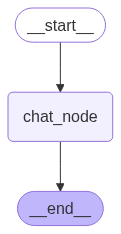

In [8]:
graph = StateGraph(state_schema = ChatState)

# Adding nodes
graph.add_node('chat_node', chat_node)

# Adding edges
graph.add_edge(START, 'chat_node')
graph.add_edge('chat_node', END)

# Compiling the graph
workflow = graph.compile(checkpointer = checkpointer)
workflow

In [9]:
CONFIG = {"configurable": {"thread_id": '1'}}
initial_state = {"messages": 'Hii, my name is Nikunj.'}

response = workflow.invoke(
    input = initial_state,
    config = CONFIG
)

In [10]:
response

{'messages': [HumanMessage(content='Hii, my name is Nikunj.', additional_kwargs={}, response_metadata={}, id='a412a7ec-312c-47f3-9d14-26804230483c'),
  AIMessage(content='Hello Nikunj! How can I assist you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 11, 'prompt_tokens': 16, 'total_tokens': 27, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_name': 'gpt-3.5-turbo-0125', 'system_fingerprint': None, 'id': 'chatcmpl-CIbWXMzD8Ltz6kiTHfKAXsxHxpSyS', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='run--e46d91f6-8aac-4864-b08b-4f09a9c1d151-0', usage_metadata={'input_tokens': 16, 'output_tokens': 11, 'total_tokens': 27, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}}),
  HumanMessage(conten

In [11]:
type(response)

dict

In [12]:
response.get('messages')

[HumanMessage(content='Hii, my name is Nikunj.', additional_kwargs={}, response_metadata={}, id='a412a7ec-312c-47f3-9d14-26804230483c'),
 AIMessage(content='Hello Nikunj! How can I assist you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 11, 'prompt_tokens': 16, 'total_tokens': 27, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_name': 'gpt-3.5-turbo-0125', 'system_fingerprint': None, 'id': 'chatcmpl-CIbWXMzD8Ltz6kiTHfKAXsxHxpSyS', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='run--e46d91f6-8aac-4864-b08b-4f09a9c1d151-0', usage_metadata={'input_tokens': 16, 'output_tokens': 11, 'total_tokens': 27, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}}),
 HumanMessage(content='What is my n

In [13]:
CONFIG = {"configurable": {"thread_id": '1'}}
initial_state = {"messages": 'What is my name?.'}

response = workflow.invoke(
    input = initial_state,
    config = CONFIG
)

In [14]:
response

# See we're getting four messages, 2 of earlier transaction and 2 of this transaction

{'messages': [HumanMessage(content='Hii, my name is Nikunj.', additional_kwargs={}, response_metadata={}, id='a412a7ec-312c-47f3-9d14-26804230483c'),
  AIMessage(content='Hello Nikunj! How can I assist you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 11, 'prompt_tokens': 16, 'total_tokens': 27, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_name': 'gpt-3.5-turbo-0125', 'system_fingerprint': None, 'id': 'chatcmpl-CIbWXMzD8Ltz6kiTHfKAXsxHxpSyS', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='run--e46d91f6-8aac-4864-b08b-4f09a9c1d151-0', usage_metadata={'input_tokens': 16, 'output_tokens': 11, 'total_tokens': 27, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}}),
  HumanMessage(conten

In [15]:
# Changing the thread_id

CONFIG = {"configurable": {"thread_id": '2'}}
initial_state = {"messages": 'What is the capital of India?'}

response = workflow.invoke(
    input = initial_state,
    config = CONFIG
)

In [16]:
response

{'messages': [HumanMessage(content='What is the capital of India?', additional_kwargs={}, response_metadata={}, id='bfcf4808-f226-4dca-831c-36acf8e2b77e'),
  AIMessage(content='The capital of India is New Delhi.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 8, 'prompt_tokens': 14, 'total_tokens': 22, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_name': 'gpt-3.5-turbo-0125', 'system_fingerprint': None, 'id': 'chatcmpl-CIbWYEECZJDP4jEq46nuN86HLkqNU', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='run--42ea0bc7-a017-4c70-ac80-8f00a227ee48-0', usage_metadata={'input_tokens': 14, 'output_tokens': 8, 'total_tokens': 22, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}}),
  HumanMessage(content='

In [17]:
# Changing the thread_id

CONFIG = {"configurable": {"thread_id": '2'}}
initial_state = {"messages": 'What was the name of MahaRana Pratap horse?'}

response = workflow.invoke(
    input = initial_state,
    config = CONFIG
)

In [18]:
response

{'messages': [HumanMessage(content='What is the capital of India?', additional_kwargs={}, response_metadata={}, id='bfcf4808-f226-4dca-831c-36acf8e2b77e'),
  AIMessage(content='The capital of India is New Delhi.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 8, 'prompt_tokens': 14, 'total_tokens': 22, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_name': 'gpt-3.5-turbo-0125', 'system_fingerprint': None, 'id': 'chatcmpl-CIbWYEECZJDP4jEq46nuN86HLkqNU', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='run--42ea0bc7-a017-4c70-ac80-8f00a227ee48-0', usage_metadata={'input_tokens': 14, 'output_tokens': 8, 'total_tokens': 22, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}}),
  HumanMessage(content='

In [19]:
# Get all the saved Threads

check_generator = checkpointer.list(config = None)
threads = set()

for thread in check_generator:
    print(thread)

CheckpointTuple(config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f09a0e9-8b59-67b5-8010-75740a2f8908'}}, checkpoint={'v': 4, 'ts': '2025-09-25T12:53:13.074270+00:00', 'id': '1f09a0e9-8b59-67b5-8010-75740a2f8908', 'channel_values': {'messages': [HumanMessage(content='What is the capital of India?', additional_kwargs={}, response_metadata={}, id='bfcf4808-f226-4dca-831c-36acf8e2b77e'), AIMessage(content='The capital of India is New Delhi.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 8, 'prompt_tokens': 14, 'total_tokens': 22, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_name': 'gpt-3.5-turbo-0125', 'system_fingerprint': None, 'id': 'chatcmpl-CIbWYEECZJDP4jEq46nuN86HLkqNU', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None

In [20]:
# Get all the saved Threads

check_generator = checkpointer.list(config = None)
threads = set()

for thread in check_generator:
    print(thread.config)

{'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f09a0e9-8b59-67b5-8010-75740a2f8908'}}
{'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f09a0e9-74e4-6882-800f-e5fefd1a793b'}}
{'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f09a0e9-74dc-64d7-800e-ac7ad22b2201'}}
{'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f09a0e9-7472-60ef-800d-07fabd867078'}}
{'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f09a0e9-5b37-6a4d-800c-0af06b8bfca4'}}
{'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f09a0e9-5b32-6c25-800b-054083b8ba9f'}}
{'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f09a0e8-f701-62af-8010-92cfaa92bb5a'}}
{'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f09a0e8-dec5-6ac6-800f-14c0725fbe50'}}
{'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f09a

In [21]:
# Get all the saved Threads

check_generator = checkpointer.list(config = None)
threads = set()

for thread in check_generator:
    thread_id = thread.config['configurable'] ['thread_id']

    threads.add(thread_id)

In [22]:
threads

{'1', '2'}

In [43]:
for thread in checkpointer.list(config = {"configurable": {'thread_id': '1'}}):
    print(thread.checkpoint['channel_values'] ['messages'])

[HumanMessage(content='Hii, my name is Nikunj.', additional_kwargs={}, response_metadata={}, id='a412a7ec-312c-47f3-9d14-26804230483c'), AIMessage(content='Hello Nikunj! How can I assist you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 11, 'prompt_tokens': 16, 'total_tokens': 27, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_name': 'gpt-3.5-turbo-0125', 'system_fingerprint': None, 'id': 'chatcmpl-CIbWXMzD8Ltz6kiTHfKAXsxHxpSyS', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='run--e46d91f6-8aac-4864-b08b-4f09a9c1d151-0', usage_metadata={'input_tokens': 16, 'output_tokens': 11, 'total_tokens': 27, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}}), HumanMessage(content='What is my nam

KeyError: 'messages'

In [44]:
def get_all_threads():

    check_generator = checkpointer.list(config = None)
    threads = set()

    for thread in check_generator:
        thread_id = thread.config['configurable'] ['thread_id']

        threads.add(thread_id)

    return list(threads)

In [45]:
get_all_threads()

['1', '2']

In [46]:
config = {"configurable": {'thread_id': '1'}}

In [62]:
for message in workflow.get_state(config = config).values['messages']:
    print(message.content)

Hii, my name is Nikunj.
Hello Nikunj! How can I assist you today?
What is my name?.
Your name is Nikunj.
Hii, my name is Nikunj.
Hello Nikunj! How can I assist you today?
What is my name?.
Your name is Nikunj.
Hii, my name is Nikunj.
Hello Nikunj! How can I assist you today?
What is my name?.
Your name is Nikunj.


In [51]:
workflow.get_state(config = config).values['messages']

[HumanMessage(content='Hii, my name is Nikunj.', additional_kwargs={}, response_metadata={}, id='a412a7ec-312c-47f3-9d14-26804230483c'),
 AIMessage(content='Hello Nikunj! How can I assist you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 11, 'prompt_tokens': 16, 'total_tokens': 27, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_name': 'gpt-3.5-turbo-0125', 'system_fingerprint': None, 'id': 'chatcmpl-CIbWXMzD8Ltz6kiTHfKAXsxHxpSyS', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='run--e46d91f6-8aac-4864-b08b-4f09a9c1d151-0', usage_metadata={'input_tokens': 16, 'output_tokens': 11, 'total_tokens': 27, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}}),
 HumanMessage(content='What is my n

In [63]:
class Name:
    def __init__(self, name, surname):
        self.name = name
        self.surname = surname

    def __str__(self):  # for user-friendly printing
        return f"{self.name} {self.surname}"

    def __repr__(self):  # for developer-friendly/debug printing
        return f"Name(name='{self.name}', surname='{self.surname}')"


In [64]:
nikunj = Name("Nikunj", "Bosamiya")
jugal = Name('Jugal', 'Bosamiya')
harshit = Name("Harshit", "Kamani")

In [65]:
l = [nikunj, jugal, harshit]

for i in l:
    print(i)

Nikunj Bosamiya
Jugal Bosamiya
Harshit Kamani


In [66]:
print(l)

[Name(name='Nikunj', surname='Bosamiya'), Name(name='Jugal', surname='Bosamiya'), Name(name='Harshit', surname='Kamani')]


In [70]:
requirements = r"D:\Nikss\Self Pracitce\GenAI using LangGraph\chatbot-in-langgraph-main\requirements.txt"


In [72]:
import pkg_resources

def check_requirements(requirements_file="requirements.txt"):
    # open with utf-16 if utf-8 fails
    try:
        with open(requirements_file, encoding="utf-8") as f:
            requirements = f.read().splitlines()
    except UnicodeError:
        with open(requirements_file, encoding="utf-16") as f:
            requirements = f.read().splitlines()

    for req in requirements:
        if not req.strip() or req.startswith("#"):  # skip empty lines or comments
            continue
        try:
            pkg_resources.require(req)
            print(f"✅ {req} is installed")
        except pkg_resources.DistributionNotFound:
            print(f"❌ {req} is NOT installed")
        except pkg_resources.VersionConflict as e:
            print(f"⚠️ {req} version conflict: {e.report()}")

if __name__ == "__main__":
    check_requirements(requirements)


✅ aiosqlite==0.21.0 is installed
✅ altair==5.5.0 is installed
✅ annotated-types==0.7.0 is installed
✅ anyio==4.9.0 is installed
✅ attrs==25.3.0 is installed
✅ blinker==1.9.0 is installed
⚠️ cachetools==6.1.0 version conflict: cachetools 5.5.2 is installed but cachetools==6.1.0 is required
⚠️ certifi==2025.7.14 version conflict: certifi 2025.4.26 is installed but certifi==2025.7.14 is required
✅ charset-normalizer==3.4.2 is installed
✅ click==8.2.1 is installed
✅ colorama==0.4.6 is installed
✅ distro==1.9.0 is installed
❌ dotenv==0.9.9 is NOT installed
✅ gitdb==4.0.12 is installed
✅ GitPython==3.1.45 is installed
⚠️ greenlet==3.2.3 version conflict: greenlet 3.2.2 is installed but greenlet==3.2.3 is required
✅ h11==0.16.0 is installed
✅ httpcore==1.0.9 is installed
✅ httpx==0.28.1 is installed
✅ idna==3.10 is installed
✅ Jinja2==3.1.6 is installed
✅ jiter==0.10.0 is installed
✅ jsonpatch==1.33 is installed
✅ jsonpointer==3.0.0 is installed
⚠️ jsonschema==4.25.0 version conflict: jsonsch